## Assignments 02

### 1.Significant earthquakes since 2150 B.C.

The Significant Earthquake Database contains information on destructive earthquakes from 2150 B.C. to the present. On the top left corner, select all columns and download the entire significant earthquake data file in .tsv format by clicking the Download TSV File button. Click the variable name for more information. Read the file (e.g., earthquakes-2026-10-14_11-23-28_+0800.tsv) as an object and name it Sig_Eqs.

1.1 [5 points] Compute the total number of deaths caused by earthquakes since 2150 B.C. in each country, and then print the top 20 countries along with the total number of deaths.

In [33]:
from turtle import down
import pandas as pd
#导入数据集
Sig_Eqs = pd.read_csv(
    "earthquakes-2026-10-14_21-39-07_+0800.tsv",
    sep="\t",
    skiprows=[1]
)

#计算总死亡数不包括次生灾害
top20_deaths = (
    Sig_Eqs.groupby("Country")["Deaths"] #分组
    .sum()#求和
    .sort_values(ascending=False)#降序排序
    .head(20)#选择前20个
)

print(top20_deaths) #打印


Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014453.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64


1.2 [10 points] Compute the total number of earthquakes with magnitude larger than 3.0 (use column Ms as the magnitude) worldwide each year, and then plot the time series. Do you observe any trend? Explain why or why not?

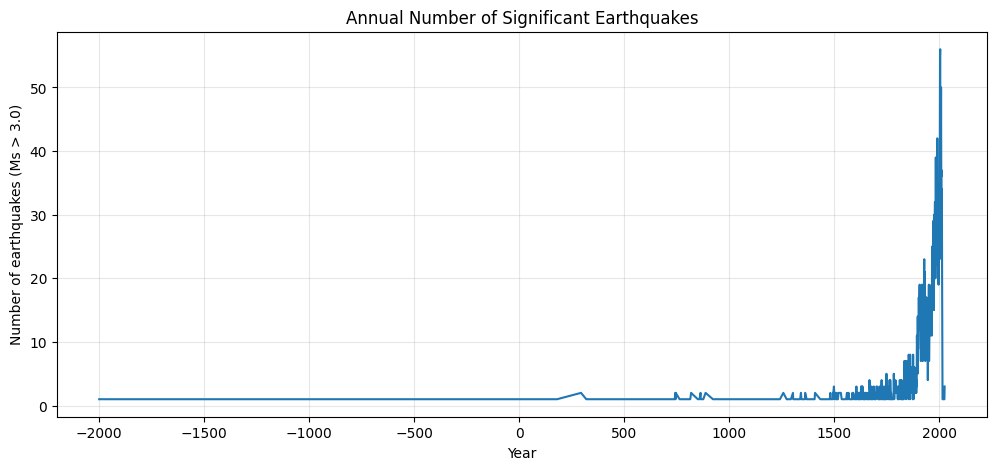

In [ ]:
from turtle import down
import pandas as pd
#导入数据集
Sig_Eqs = pd.read_csv(
    "earthquakes-2026-10-14_21-39-07_+0800.tsv",
    sep="\t",
    skiprows=[1]
)

#计算记录大于3的数量
earthquakes_per_year  = (
    Sig_Eqs[Sig_Eqs["Ms"]>3.0]#筛选大于3的地震
    .groupby("Year") #分组
    .size()#求记录总数
)

import matplotlib.pyplot as plt

ax = earthquakes_per_year.plot(figsize=(12, 5))

ax.set_xlabel("Year")#x轴标题
ax.set_ylabel("Number of earthquakes (Ms > 3.0)")#y轴标题
ax.set_title("Annual Number of Significant Earthquakes")#标题
ax.grid(alpha=0.3)

plt.show()

从图中可以看到在公元1500前地震数量较少，在这之后呈现增加趋势，特别是20世纪以后增加明显，同时也存在明显波动。最后面突然降低是因为没有记录到完整年份。
但是，这不能直接证明真实地震发生频率一直在增加。古代地震主要依赖历史资料，记录不完整；近现代地震仪器、监测台站和资料收集系统不断完善，使更多地震能够被探测和记录。此外，Ms 震级数据本身的可用性也会影响统计结果。因此，图中趋势很大程度上可能反映观测和记录能力的变化，而不完全是地震活动本身的变化。

1.3 [10 points] Write a function CountEq_LargestEq that returns (a) the total number of earthquakes since 2150 B.C. in a given country AND (b) date and location of the largest earthquake ever happened in this country. Apply CountEq_LargestEq to every country in the file, report your results in a descending order.

In [54]:
import pandas as pd

Sig_Eqs = pd.read_csv(
    "earthquakes-2026-10-14_21-39-07_+0800.tsv",
    sep="\t",
    skiprows=[1]
)  # 读取 TSV 文件，跳过第二行搜索参数


def CountEq_LargestEq(Con):
    country_data = Sig_Eqs[Sig_Eqs["Country"] == Con]  # 筛选指定国家
    num = len(country_data)  # 统计地震记录总数

    if country_data["Ms"].notna().any():  # 检查该国是否有 Ms 记录
        largest_eq = country_data.loc[country_data["Ms"].idxmax()]  # 取 Ms 最大的记录
        largest_Y = int(largest_eq["Year"])  # 提取年份并转为整数
        largest_M = int(largest_eq["Mo"]) if pd.notna(largest_eq["Mo"]) else "?"  # 提取月份
        largest_D = int(largest_eq["Dy"]) if pd.notna(largest_eq["Dy"]) else "?"  # 提取日期
        largest_date = f"{largest_Y}-{largest_M}-{largest_D}"  # 合并日期
        largest_pos = largest_eq["Location Name"]  # 提取地震位置
    else:
        largest_date, largest_pos = "Unknown", "Unknown"  # 没有 Ms 时无法确定最大地震

    return Con, num, largest_date, largest_pos  # 返回该国的统计结果


results = []  # 创建列表保存各国结果
for country in Sig_Eqs["Country"].dropna().unique():  # 遍历所有不重复国家
    results.append(CountEq_LargestEq(country))  # 调用函数并保存结果

all_countries = pd.DataFrame(  # 将结果转换为 DataFrame
    results,
    columns=["Country", "Total Earthquakes", "Largest Date", "Largest Location"]
)

all_countries = all_countries.sort_values(  # 按地震总数降序排列
    by="Total Earthquakes",
    ascending=False
).reset_index(drop=True)  # 重置行索引

print(all_countries.to_string(index=False))  # 输出所有国家的结果


                                     Country  Total Earthquakes Largest Date                                     Largest Location
                                       CHINA                626   1920-12-16              CHINA:  GANSU PROVINCE, SHANXI PROVINCE
                                       JAPAN                429     869-7-13                                      JAPAN:  SANRIKU
                                   INDONESIA                427   2004-12-26          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
                                        IRAN                385    856-12-22                                IRAN:  DAMGHAN, QUMIS
                                      TURKEY                359   1939-12-26                                    TURKEY:  ERZINCAN
                                       ITALY                338    1915-1-13                   ITALY:  MARSICA, AVEZZANO, ABRUZZI
                                      GREECE                296     365-7-21              

### 2. Air temperature in Shenzhen 1998-2022

In this problem set, we will examine how air temperature changes in Shenzhen from 1998 to 2022 using the hourly weather data measured at the Baoan International Airport. The data set is from NOAA Integrated Surface Dataset. Download the zipped file Baoan_Weather_1998_2022.zip, unzip it, and move the Baoan_Weather_1998_2022.csv file to your working directory.

Read page 10-11 (POS 88-92 and POS 93-93) of the comprehensive user guide for the detailed format of the air temperature data (use column TMP). Explain how you filter the data in your report.

[10 points] Plot monthly averaged air temperature against the observation time. Is there a trend in monthly averaged air temperature from 1998 to 2022?

根据 ISD 指导手册，将 TMP 中的温度值除以 10 转换为摄氏度，剔除 +9999 缺测值，并仅保留质量码为 1 或 5 的观测，因为这两种质量码均表示数据通过全部质量检查

In [ ]:
import pandas as pd
weather = pd.read_csv(
    "Baoan_Weather_1998_2022.csv",
    usecols=["DATE", "TMP"],
    parse_dates=["DATE"]
)  # 只读取观测时间和气温，并将 DATE 转为日期时间
tmp_parts = weather["TMP"].str.split(",", n=1, expand=True)  # 拆分气温和质量码
weather["temp_c"] = pd.to_numeric(tmp_parts[0]) / 10  # 将 0.1℃ 转换为 ℃
weather["quality_code"] = tmp_parts[1]  # 提取质量码
weather_clean = weather.loc[
    (tmp_parts[0] != "+9999") & weather["quality_code"].isin(["1", "5"]),
    ["DATE", "temp_c"]
].copy()  # 删除缺测值，仅保留通过全部质量检查的记录
print(weather_clean.head())
print(len(weather_clean))  # 查看筛选后的记录数

                 DATE  temp_c
0 1998-01-01 00:00:00    18.6
1 1998-01-01 01:00:00    22.0
2 1998-01-01 02:00:00    24.0
3 1998-01-01 03:00:00    22.1
4 1998-01-01 04:00:00    24.0
234864


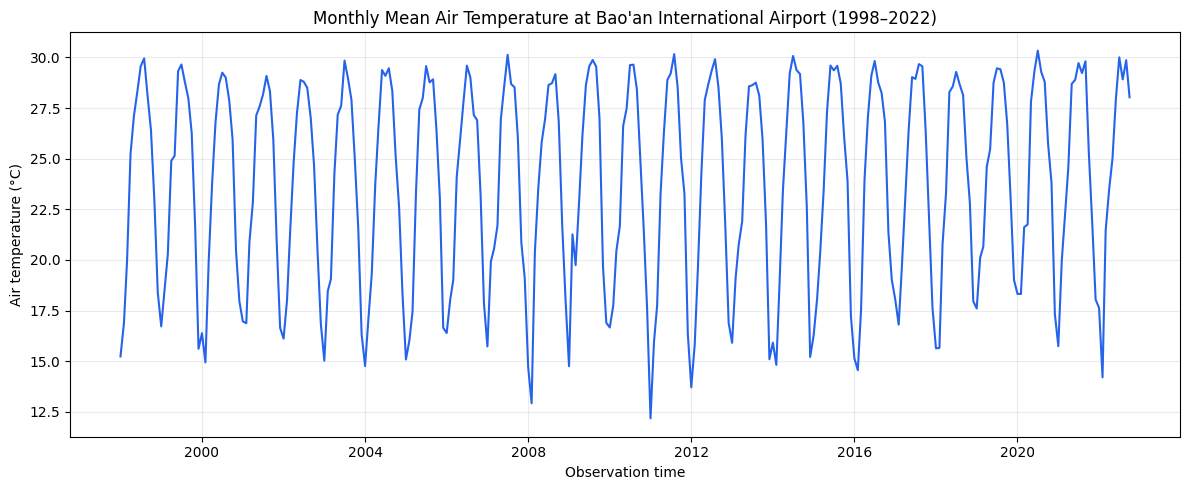

In [62]:
import matplotlib.pyplot as plt
monthly_temp = (
    weather_clean.set_index("DATE")["temp_c"]
    .resample("MS")
    .mean()
)  # 按月份分组计算平均气温，日期标记为每月第一天
fig, ax = plt.subplots(figsize=(12, 5))  # 创建画布和坐标轴
ax.plot(
    monthly_temp.index,
    monthly_temp.values,
    color="#2563EB",
    linewidth=1.5
)  # 绘制月平均气温时间序列
ax.set_title("Monthly Mean Air Temperature at Bao'an International Airport (1998–2022)")
ax.set_xlabel("Observation time")  # 设置横轴标题
ax.set_ylabel("Air temperature (°C)")  # 设置纵轴标题
ax.grid(alpha=0.25)  # 添加浅色网格线
fig.tight_layout()  # 自动调整布局，避免文字被截断
plt.show()


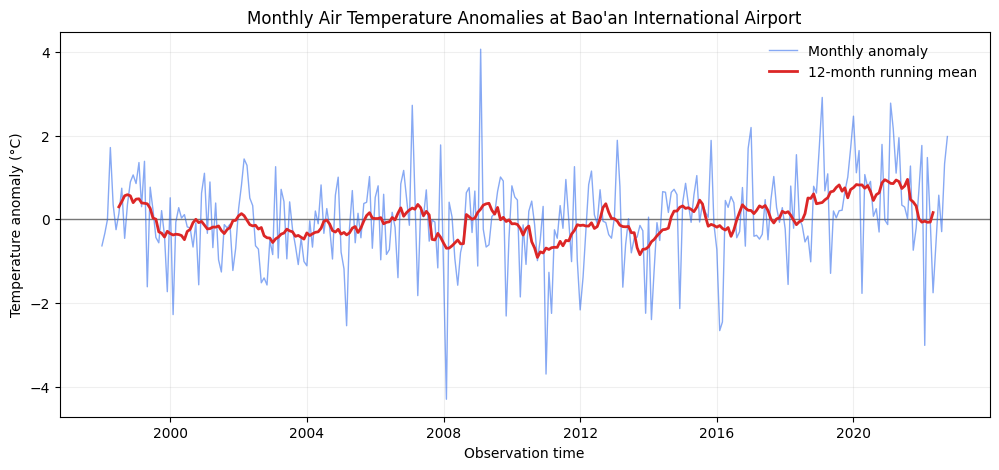

In [63]:
import numpy as np
import matplotlib.pyplot as plt

monthly_climatology = monthly_temp.groupby(
    monthly_temp.index.month
).transform("mean")  # 计算每个日历月在1998—2022年的平均气温

monthly_anomaly = monthly_temp - monthly_climatology  # 月气温减去对应月份的气候平均值
running_anomaly = monthly_anomaly.rolling(12, center=True).mean()  # 计算12个月滑动平均

fig, ax = plt.subplots(figsize=(12, 5))

ax.axhline(0, color="#777777", linewidth=1)  # 添加距平零线
ax.plot(
    monthly_anomaly.index,
    monthly_anomaly.values,
    color="#2563EB",
    linewidth=1,
    alpha=0.55,
    label="Monthly anomaly"
)  # 绘制逐月距平

ax.plot(
    running_anomaly.index,
    running_anomaly.values,
    color="#DC2626",
    linewidth=2,
    label="12-month running mean"
)  # 绘制12个月滑动平均，便于观察长期变化

ax.set_title("Monthly Air Temperature Anomalies at Bao'an International Airport")
ax.set_xlabel("Observation time")
ax.set_ylabel("Temperature anomaly (°C)")
ax.grid(alpha=0.2)
ax.legend(frameon=False)


图中可以看到非常明显的季节变化：夏季气温高、冬季气温低。
去除季节循环后，月平均气温距平仍然表现出明显的年际波动。12 个月滑动平均显示，研究期内冷暖阶段交替出现，并非持续升温；但后期正距平相对较多，线性拟合表明 1998—2022 年整体呈弱升温趋势，升温速率约为 0.023℃/年。

### 3. Global collection of hurricanes

The International Best Track Archive for Climate Stewardship (IBTrACS) project is the most complete global collection of tropical cyclones available. It merges recent and historical tropical cyclone data from multiple agencies to create a unified, publicly available, best-track dataset that improves inter-agency comparisons. IBTrACS was developed collaboratively with all the World Meteorological Organization (WMO) Regional Specialized Meteorological Centers, as well as other organizations and individuals from around the world.

In this problem set, we will use all storms available in the IBTrACS record since 1842. Download the zipped file ibtracs.ALL.list.v04r00.zip, unzip it, and move the ibtracs.ALL.list.v04r00.csv file to your working directory. Read Column Variable Descriptions for variables in the file. Examine the first few lines of the file.

Below we provide an example to load the file as a pandas dataframe. Think about the options being used and why, and modify when necessary.

df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),
                 skiprows=[1, 2], 
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])
df.head()

3.1 [5 points] Group the data on Storm Identifie (SID), report names (NAME) of the 10 largest hurricanes according to wind speed (WMO_WIND).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "ibtracs.ALL.list.v04r00.csv",
    usecols=range(17),  # 只读取前17列
    skiprows=[1],  # 跳过第二行的单位说明
    skipinitialspace=True,  # 去除分隔符后的空格，正确识别缺测值
    parse_dates=["ISO_TIME"],  # 将观测时间转为日期时间
    na_values=["NOT_NAMED", "NAME"],  # 将无名风暴标记为缺失值
    low_memory=False
)

for col in ["LAT", "LON", "WMO_WIND"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")  # 转为数值，无效值设为NaN

storm_max = df.groupby("SID").agg(
    NAME=("NAME", "first"),
    MAX_WIND=("WMO_WIND", "max")
)  # 按风暴ID提取名称和最大风速

top10_names = storm_max.nlargest(10, "MAX_WIND")["NAME"].fillna("NOT_NAMED")  # 取前10个名称
print(top10_names.to_string(index=False, header=False))  # 只输出风暴名称

 PATRICIA
    ALLEN
NOT_NAMED
  GILBERT
    LINDA
    WILMA
   DORIAN
    MITCH
     RITA
     RICK


3.2 [5 points] List the wind speed (WMO_WIND) of the 20 strongest-wind hurricanes.

In [2]:
top20_winds = storm_max["MAX_WIND"].nlargest(20)  # 每个风暴取最大风速，再选前20个
print(top20_winds.to_string())  # 输出SID及对应最大风速（节）

SID
2015293N13266    185.0
1980214N11330    165.0
1935241N23291    160.0
1988253N12306    160.0
1997253N12255    160.0
2005289N18282    160.0
2019236N10314    160.0
1998295N12284    155.0
2005261N21290    155.0
2009288N07267    155.0
2017242N16333    155.0
1932304N15305    150.0
1955265N13307    150.0
1959249N19181    150.0
1969226N18280    150.0
1977242N27272    150.0
1979238N12324    150.0
1992230N11325    150.0
1994222N11267    150.0
2005236N23285    150.0


3.3 [5 points] Count all datapoints by Basin.

In [3]:
basin_counts = df["BASIN"].value_counts(dropna=False)  # 统计各海域记录数，包括海域缺失的记录
print(basin_counts.to_string())  # 输出各海域的数据点数量

BASIN
WP     236576
SI     160668
NaN    124881
SP      67119
EP      62412
NI      55402
SA        119


3.4 [5 points] Make a hexbin plot of the location of datapoints in Latitude and Longitude.

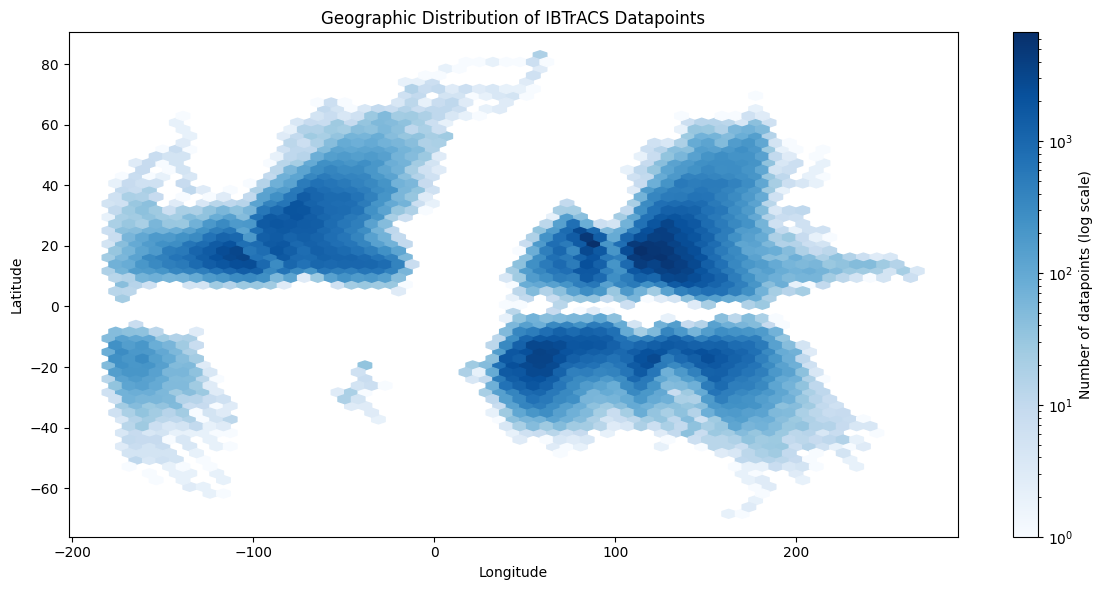

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

hb = ax.hexbin(
    df["LON"],
    df["LAT"],
    gridsize=60,
    bins="log",
    mincnt=1,
    cmap="Blues"
)  # 用六边形统计经纬度位置的数据点密度

fig.colorbar(hb, ax=ax, label="Number of datapoints (log scale)")  # 添加对数密度颜色条
ax.set_title("Geographic Distribution of IBTrACS Datapoints")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

fig.tight_layout()
plt.show()

3.5 [5 points] Find Typhoon Mangkhut (from 2018) and plot its track.

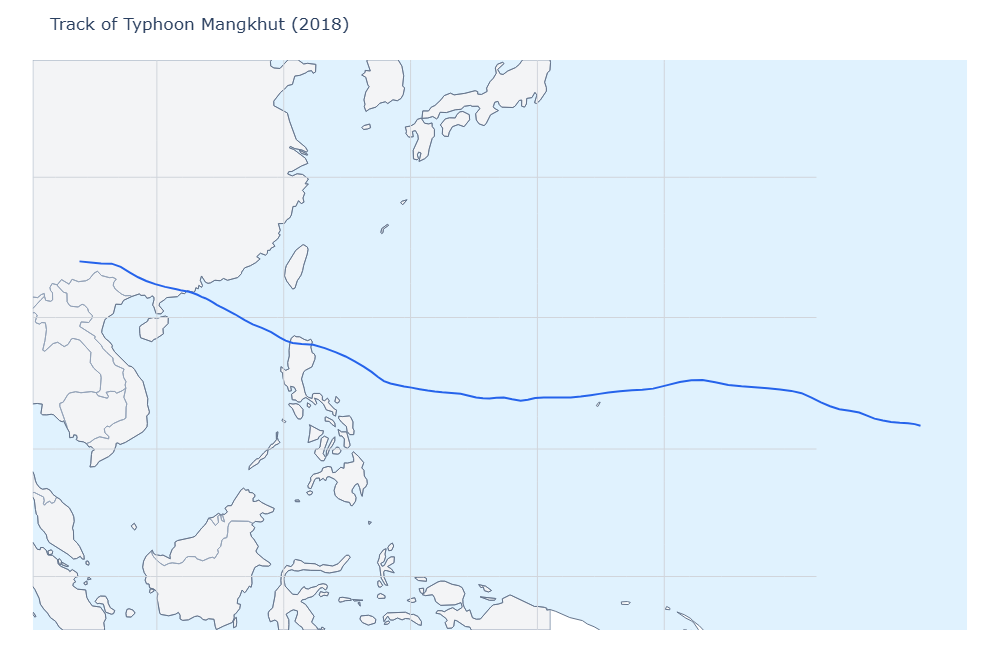

In [5]:
import plotly.graph_objects as go

mangkhut = df[
    df["NAME"].eq("MANGKHUT") & df["SEASON"].eq(2018)
].sort_values("ISO_TIME")  # 筛选2018年台风山竹并按时间排序

fig = go.Figure(go.Scattergeo(
    lon=mangkhut["LON"],
    lat=mangkhut["LAT"],
    mode="lines",
    line=dict(color="#2563EB", width=2)
))  # 在地图上绘制台风路径

fig.update_geos(
    scope="asia",
    fitbounds="locations",  # 根据轨迹自动调整地图范围
    showcoastlines=True,
    coastlinecolor="#64748B",
    showland=True,
    landcolor="#F3F4F6",
    showocean=True,
    oceancolor="#E0F2FE",
    showcountries=True,
    countrycolor="#94A3B8",
    lataxis=dict(showgrid=True, gridcolor="#D1D5DB", dtick=10),
    lonaxis=dict(showgrid=True, gridcolor="#D1D5DB", dtick=10)
)  # 添加海岸线、国界、陆地和海洋

fig.update_layout(
    title="Track of Typhoon Mangkhut (2018)",
    width=1000,
    height=650,
    margin=dict(l=20, r=20, t=60, b=20),
    showlegend=False
)

fig.show(renderer="png")  # 显示普通静态地图

3.6 [5 points] Create a filtered dataframe that contains only data since 1970 from the Western North Pacific (“WP”) and Eastern North Pacific (“EP”) Basin. Use this for the rest of the problem set.

In [6]:
df_filtered = df[
    (df["ISO_TIME"].dt.year >= 1970) & df["BASIN"].isin(["WP", "EP"])
].copy()  # 筛选1970年以来WP和EP海域的记录

print("Filtered datapoints:", len(df_filtered))  # 输出筛选后的记录数
print("Basins:", df_filtered["BASIN"].unique())  # 核对海域
print("Date range:", df_filtered["ISO_TIME"].min(), "to", df_filtered["ISO_TIME"].max())  # 核对时间

Filtered datapoints: 176352
Basins: <StringArray>
['WP', 'EP']
Length: 2, dtype: str
Date range: 1970-02-19 00:00:00 to 2022-10-12 18:00:00


3.7 [5 points] Plot the number of datapoints per day.

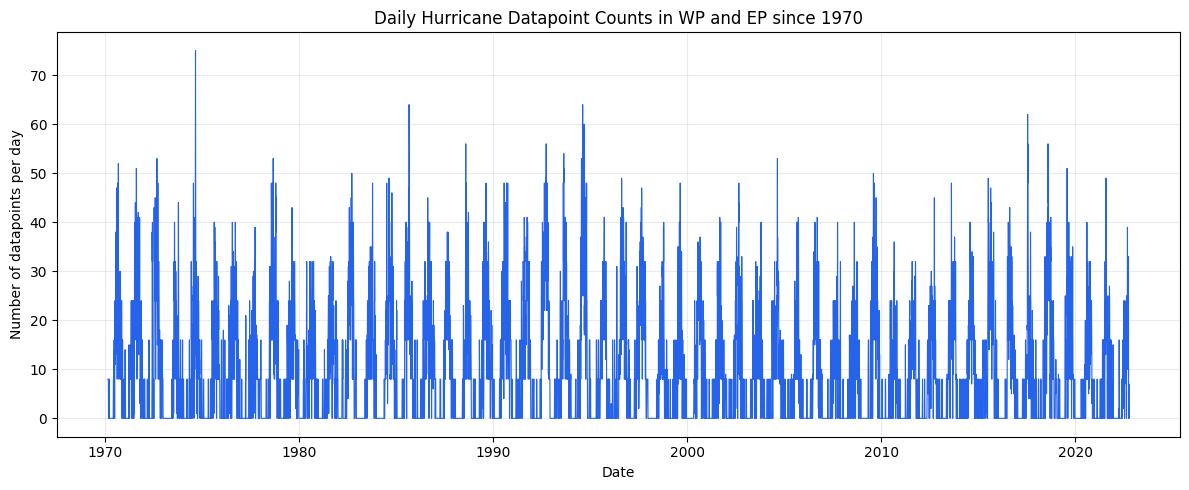

In [7]:
daily_counts = df_filtered.set_index("ISO_TIME").resample("D").size()  # 统计每天的数据点数

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_counts.index, daily_counts.values, color="#2563EB", linewidth=0.8)  # 绘制每日计数
ax.set_title("Daily Hurricane Datapoint Counts in WP and EP since 1970")
ax.set_xlabel("Date")
ax.set_ylabel("Number of datapoints per day")
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

3.8 [5 points] Calculate the climatology of datapoint counts as a function of day of year. The day of year is the sequential day number starting with day 1 on January 1st.

In [8]:
daily_climatology = daily_counts.groupby(daily_counts.index.dayofyear).mean()  # 计算各年内日的平均计数
daily_climatology.index.name = "Day of year"  # 设置索引名称

print(daily_climatology.head(10).to_string())  # 查看前10个年内日的气候态

Day of year
1     1.596154
2     1.384615
3     1.423077
4     1.788462
5     2.019231
6     2.326923
7     2.173077
8     2.788462
9     2.653846
10    2.634615


3.9 [5 points] Calculate the anomaly of daily counts from the climatology.

In [9]:
daily_anomaly = daily_counts - daily_climatology.loc[
    daily_counts.index.dayofyear
].to_numpy()  # 每日计数减去对应年内日的气候平均计数

print(daily_anomaly.head(10).to_string())  # 查看前10天的距平

ISO_TIME
1970-02-19    7.018868
1970-02-20    7.094340
1970-02-21    7.188679
1970-02-22    7.377358
1970-02-23    7.490566
1970-02-24    7.547170
1970-02-25    7.396226
1970-02-26    7.245283
1970-02-27    6.905660
1970-02-28   -0.150943
Freq: D


3.10 [5 points] Resample the anomaly timeseries at annual resolution and plot. So which years stand out as having anomalous hurricane activity?

ISO_TIME
2010-12-31   -4.570616
1992-12-31    4.537501
1994-12-31    4.415686
1997-12-31    3.330754
1990-12-31    3.073220


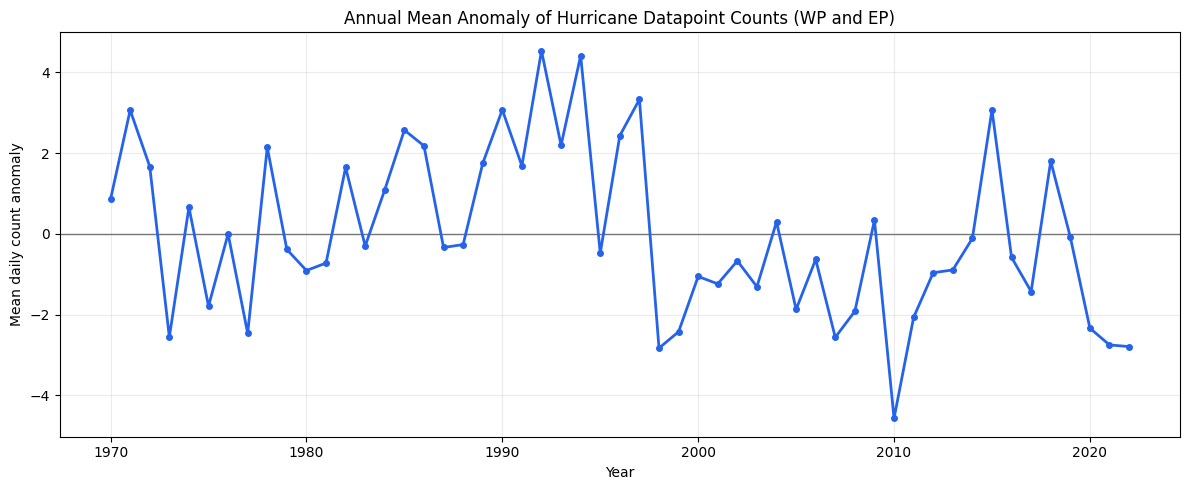

In [10]:
annual_anomaly = daily_anomaly.resample("YE").mean()  # 将每日距平重采样为年平均距平

standout_years = annual_anomaly.abs().nlargest(5)  # 找出绝对距平最大的5年
print(annual_anomaly.loc[standout_years.index].to_string())  # 输出异常最突出的年份

fig, ax = plt.subplots(figsize=(12, 5))
ax.axhline(0, color="#777777", linewidth=1)  # 添加零距平参考线
ax.plot(
    annual_anomaly.index.year,
    annual_anomaly.values,
    color="#2563EB",
    linewidth=2,
    marker="o",
    markersize=4
)  # 绘制年平均距平

ax.set_title("Annual Mean Anomaly of Hurricane Datapoint Counts (WP and EP)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean daily count anomaly")
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

1992 年和 1994 年的正距平最为突出，表明白天风数据点计数所反映的气旋活动整体偏强；2010 年的负距平最大，表明气旋活动整体偏弱。此外，1997、1990 和 2015 年也表现为较明显的正距平。

### 4. Explore a data set

4.1 [5 points] Load the csv, XLS, or XLSX file, and clean possible data points with missing values or bad quality.

In [11]:
import pandas as pd

n2o_data = pd.read_csv("adr_n2o_clean.csv", parse_dates=["time"])  # 直接读取CSV
original_count = len(n2o_data)  # 保存清洗前的记录数

n2o_data["n2o_ppb"] = pd.to_numeric(n2o_data["n2o_ppb"], errors="coerce")  # 转为数值
n2o_data = n2o_data.dropna(subset=["time", "n2o_ppb"])  # 删除缺失记录
n2o_data = n2o_data[n2o_data["n2o_ppb"] > 0]  # 删除非正浓度
n2o_data = n2o_data.drop_duplicates(subset=["time"], keep="first")  # 删除重复时间
n2o_data = n2o_data.sort_values("time").reset_index(drop=True)  # 按时间排序

print("Removed records:", original_count - len(n2o_data))  # 输出删除的记录数
print("Valid records:", len(n2o_data))  # 输出有效记录数
print(n2o_data.head().to_string(index=False))  # 查看前5行

Removed records: 0
Valid records: 6093
               time   n2o_ppb
1978-07-01 01:05:00 299.72840
1978-07-01 02:06:00 304.85797
1978-07-01 03:07:00 304.85797
1978-07-01 07:10:00 301.84058
1978-07-01 08:11:00 304.85797


4.2 [5 points] Plot the time series of a certain variable.

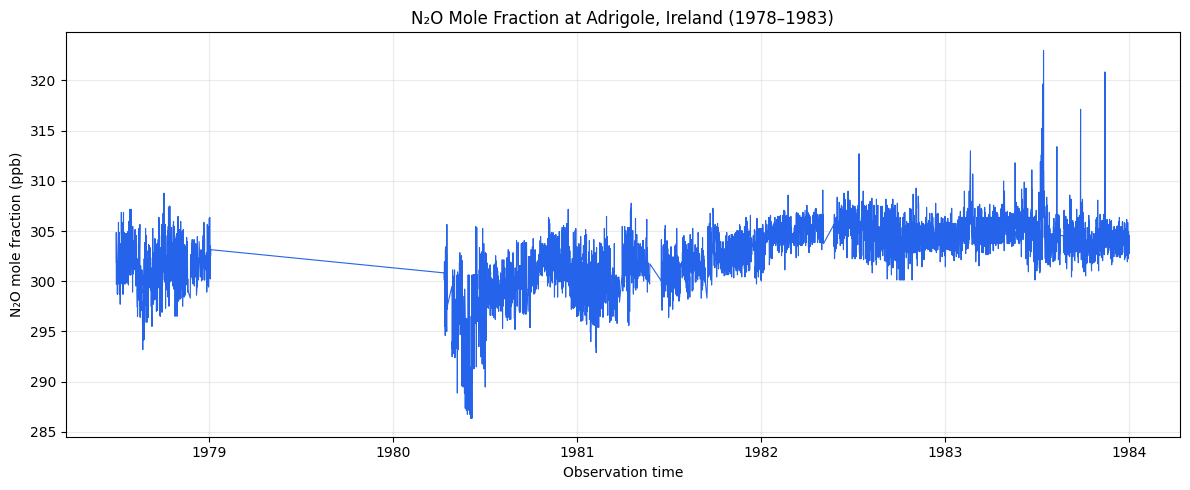

In [12]:
import matplotlib.pyplot as plt

n2o_plot = pd.read_csv("adr_n2o_clean.csv", parse_dates=["time"])  # 读取清洗后的CSV

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(n2o_plot["time"], n2o_plot["n2o_ppb"], color="#2563EB", linewidth=0.8)  # 绘制N₂O时间序列
ax.set_title("N₂O Mole Fraction at Adrigole, Ireland (1978–1983)")
ax.set_xlabel("Observation time")
ax.set_ylabel("N₂O mole fraction (ppb)")
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

4.3 [5 points] Conduct at least 5 simple statistical checks with the variable, and report your findings.

In [13]:
import numpy as np

n2o_stats_data = pd.read_csv("adr_n2o_clean.csv", parse_dates=["time"])  # 读取清洗后的CSV
values = n2o_stats_data["n2o_ppb"]  # 提取N₂O浓度列

x_years = (n2o_stats_data["time"] - n2o_stats_data["time"].min()).dt.days / 365.25  # 时间转换为年
trend = np.polyfit(x_years, values, 1)[0]  # 计算线性变化趋势

statistics = pd.Series({
    "Valid observations": values.count(),
    "Mean (ppb)": values.mean(),
    "Median (ppb)": values.median(),
    "Standard deviation (ppb)": values.std(),
    "Minimum (ppb)": values.min(),
    "25th percentile (ppb)": values.quantile(0.25),
    "75th percentile (ppb)": values.quantile(0.75),
    "Maximum (ppb)": values.max(),
    "Skewness": values.skew(),
    "Linear trend (ppb/year)": trend
})  # 计算描述性统计和变化趋势

print(statistics.round(4).to_string())  # 输出统计结果
print("Time range:", n2o_stats_data["time"].min(), "to", n2o_stats_data["time"].max())  # 输出时间范围

Valid observations          6093.0000
Mean (ppb)                   302.6080
Median (ppb)                 302.9470
Standard deviation (ppb)       3.0711
Minimum (ppb)                286.3513
25th percentile (ppb)        300.9354
75th percentile (ppb)        304.6568
Maximum (ppb)                322.9624
Skewness                      -0.8176
Linear trend (ppb/year)        0.8217
Time range: 1978-07-01 01:05:00 to 1983-12-31 20:05:00


清洗后保留 **6093 条**有效观测，原始数据没有缺失值、非正浓度或重复时间，因此删除 **0 条**记录。N₂O 平均浓度为 **302.61 ppb**，中位数为 **302.95 ppb**，标准差约为 **3.07 ppb**，观测范围为 **286.35—322.96 ppb**。偏度约为 **−0.82**，说明分布呈一定左偏。简单线性拟合得到约 **0.822 ppb/年**的上升趋势；该结果仅描述 1978—1983 年样本期内的总体变化，不能仅凭此判断趋势具有统计显著性。